## Workflow and Graph

In [81]:
from __future__ import annotations

import operator
from typing import TypedDict, List, Annotated

from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send
import os
from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage, HumanMessage

import psycopg
from psycopg.rows import dict_row
from langgraph.checkpoint.postgres import PostgresSaver
from dotenv import load_dotenv

load_dotenv()

True

### Extracting database url 

In [82]:
# function to load database
def get_database_url():
    database_url = os.getenv("DATABASE_URL")

    if not database_url:
        raise ValueError(
            "DATABASE_URL is missing. Please add your Render PostgreSQL External Database URL to .env"
        )

    if "sslmode=" not in database_url:
        separator = "&" if "?" in database_url else "?"
        database_url = f"{database_url}{separator}sslmode=require"

    return database_url

   

In [83]:
GROQ_API_KEY = os.getenv("GROQ_API_KEY")
if not GROQ_API_KEY:
    raise ValueError("GROQ_API_KEY is missing. Please add it to your .env file.")

In [84]:
class Task(BaseModel):
    id: int
    title: str
    brief: str = Field(..., description="What to cover")

In [85]:
class Plan(BaseModel):
    blog_title: str
    tasks: List[Task]

In [86]:
class State(TypedDict):
    topic: str
    plan: Plan
    # reducer: results from workers get concatenated automatically
    sections: Annotated[List[str], operator.add]
    final: str

In [87]:
llm = ChatGroq(
    model="openai/gpt-oss-120b",
    api_key=GROQ_API_KEY
)


### Orchestrator Node

In [88]:
def orchestrator(state: State) -> dict:

    plan = llm.with_structured_output(Plan).invoke(
        [
            SystemMessage(
                content=(
                    "Create a blog plan with 5-7 sections on the following topic."
                )
            ),
            HumanMessage(content=f"Topic: {state['topic']}"),
        ]
    )
    return {"plan": plan}

### fanout function to allocate one agent to on task

In [89]:
def fanout(state: State):
    return [Send("worker", {"task": task, "topic": state["topic"], "plan": state["plan"]})
            for task in state["plan"].tasks]

### Worker node (Agent for serach content )

In [90]:
def worker(payload: dict) -> dict:

    # payload contains what we sent
    task = payload["task"]
    topic = payload["topic"]
    plan = payload["plan"]

    blog_title = plan.blog_title

    section_md = llm.invoke(
        [
            SystemMessage(content="Write one clean Markdown section."),
            HumanMessage(
                content=(
                    f"Blog: {blog_title}\n"
                    f"Topic: {topic}\n\n"
                    f"Section: {task.title}\n"
                    f"Brief: {task.brief}\n\n"
                    "Return only the section content in Markdown."
                )
            ),
        ]
    ).content.strip()

    return {"sections": [section_md]}

### Reducer agent for Merging content from diffrent agent

In [91]:
# from pathlib import Path

# def reducer(state: State) -> dict:
    
#     title = state["plan"].blog_title
#     body = "\n\n".join(state["sections"]).strip()

#     final_md = f"# {title}\n\n{body}\n"

#     # ---- save to file ----
#     filename = title.lower().replace(" ", "_") + ".md"
#     output_path = Path(filename)
#     output_path.write_text(final_md, encoding="utf-8")

#     return {"final": final_md}


# from pathlib import Path

# def reducer(state: State) -> dict:
#     title = state["plan"].blog_title
#     body = "\n\n".join(state["sections"]).strip()

#     final_md = f"# {title}\n\n{body}\n"

#     # Save inside an output folder
#     output_dir = Path("output")
#     output_dir.mkdir(parents=True, exist_ok=True)

#     filename = title.lower().replace(" ", "_") + ".md"
#     output_path = output_dir / filename

#     output_path.write_text(final_md, encoding="utf-8")

#     print("Saved file:", output_path.resolve())
#     print("File exists:", output_path.exists())
#     print("File extension:", output_path.suffix)

#     return {"final": final_md}



from pathlib import Path

def reducer(state: State) -> dict:
    title = state["plan"].blog_title
    sections = state["sections"]

    print("Title:", repr(title))
    print("Number of sections:", len(sections))
    print("Section lengths:", [len(s) for s in sections])

    body = "\n\n".join(sections).strip()
    final_md = f"# {title}\n\n{body}\n"

    output_dir = Path("output")
    output_dir.mkdir(parents=True, exist_ok=True)

    filename = title.lower().replace(" ", "_") + ".md"
    output_path = output_dir / filename

    output_path.write_text(final_md, encoding="utf-8")

    print("Saved to:", output_path.resolve())
    print("Characters written:", output_path.stat().st_size)
    print("First 200 characters:", repr(output_path.read_text(encoding="utf-8")[:200]))

    return {"final": final_md}


### Graph and Workflow

In [92]:
g = StateGraph(State)
g.add_node("orchestrator", orchestrator)
g.add_node("worker", worker)
g.add_node("reducer", reducer)

g.add_edge(START, "orchestrator")
g.add_conditional_edges("orchestrator", fanout, ["worker"])
g.add_edge("worker", "reducer")
g.add_edge("reducer", END)

### Checkpointers

In [93]:
# =========================
# PostgreSQL Checkpointer
# =========================
DATABASE_URL = get_database_url()

_conn = psycopg.connect(
    DATABASE_URL,
    autocommit=True,
    row_factory=dict_row
)

checkpointer = PostgresSaver(_conn)
checkpointer.setup()

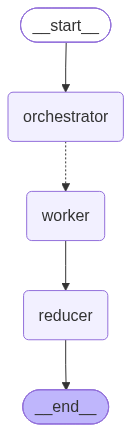

In [94]:
app = g.compile(checkpointer=checkpointer)

app

### Thread id 

In [95]:
config = {
        "configurable": {
            "thread_id": "test_thread_id"
        }
    }

In [96]:
out = app.invoke({"topic": "Write a blog on Self Attention", "sections": []}, config=config)

Title: 'Demystifying Self‑Attention: The Core of Modern Deep Learning'
Number of sections: 55
Section lengths: [3366, 3084, 5228, 2381, 7481, 5962, 2996, 3637, 3195, 4199, 3343, 5691, 5231, 4214, 3607, 2852, 3901, 7438, 2351, 3914, 3155, 2926, 3039, 2633, 5751, 10115, 4059, 2605, 2749, 4237, 3039, 6778, 5588, 2677, 3508, 2691, 3071, 4272, 3587, 6097, 5357, 1837, 2168, 4413, 5649, 3635, 4064, 2563, 2492, 2188, 4455, 4451, 5636, 2552, 3003]
Saved to: C:\AI_Engineer\BlogWriter-Agent\notebooks\output\demystifying_self‑attention:_the_core_of_modern_deep_learning.md
Characters written: 232125
First 200 characters: '# Demystifying Self‑Attention: The Core of Modern Deep Learning\n\n## Introduction to Attention Mechanisms\n\nIn the early days of deep learning, neural networks processed information **sequentially** or '


In [97]:
out

{'topic': 'Write a blog on Self Attention',
 'plan': Plan(blog_title='Demystifying Self‑Attention: The Core of Modern Deep Learning', tasks=[Task(id=1, title='Introduction – Why Self‑Attention Matters', brief='Set the stage by explaining the rise of attention mechanisms, their impact on NLP and vision, and the motivation for diving into self‑attention.'), Task(id=2, title='What Is Self‑Attention?', brief='Define self‑attention in plain language, contrast it with traditional attention, and outline the high‑level intuition of “looking at oneself”.'), Task(id=3, title='The Mathematics Behind Self‑Attention', brief='Break down the query‑key‑value formulation, scaling factor, softmax weighting, and the matrix‑multiplication steps, with simple visual examples.'), Task(id=4, title='Self‑Attention in the Transformer Architecture', brief='Show how self‑attention layers are stacked, combined with feed‑forward networks, positional encodings, and multi‑head attention to build a transformer block.'

In [105]:
import os
os.startfile(r"C:\AI_Engineer\BlogWriter-Agent\notebooks\output\blog.md")